# 01 — Momentum Factor Data Exploration

## Objective

Download, clean, validate, visualize, and save Kenneth French's official
**daily and monthly momentum factor returns**.

The official factor is a Fama–French-style momentum factor, not the stock-level
NYSE-decile P10–P1 portfolio reconstructed in Notebook 03.

**Data source:** [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)

**Units:** French downloads are in percent; this notebook converts them to
decimal returns (e.g., 1.5% becomes 0.015).

**Outputs:**
- `data/processed/01_momentum_daily.parquet`
- `data/processed/01_momentum_monthly.parquet`

Notebook 02 reads these exact outputs. Both notebooks use the same cache-first Python loader; either can run first.

**Role after the repository refactor:** This notebook is exploration and validation only. The official data pipeline is `scripts/01_get_data.py` and `scripts/02_build_dataset.py`; all reported results are generated by package code and the ordered scripts, not by notebook execution. Paths/configuration are project-relative. Original notebook snapshots are preserved privately under `data/interim/refactor_baseline_20261101/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from momentum_risk_project.data import load_momentum_returns

daily_clean, monthly_clean = load_momentum_returns()


## 1. Load daily momentum returns (cache-first)

The shared loader checks `data/processed/01_momentum_daily.parquet` first. If it is absent, the loader downloads the Kenneth French daily momentum factor, converts percentages to decimals, validates it, and saves the cache. The same rule applies independently to the monthly factor. Use `load_momentum_returns(force_download=True)` to refresh both datasets.

In [2]:
print('Daily rows:', len(daily_clean))
print('Daily date range:', daily_clean.index.min(), 'to', daily_clean.index.max())
print(daily_clean.head())

Daily rows: 26216
Daily date range: 1926-11-03 00:00:00 to 2026-08-31 00:00:00
               mom
date              
1926-11-03  0.0140
1926-11-04 -0.0025
1926-11-05  0.0092
1926-11-06 -0.0167
1926-11-08 -0.0012


In [3]:
daily_clean.head()

,mom
date,
1926-11-03,0.0140
1926-11-04,-0.0025
1926-11-05,0.0092
1926-11-06,-0.0167
1926-11-08,-0.0012


In [4]:
daily_df = daily_clean.copy()
print(daily_df.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 26216 entries, 1926-11-03 to 2026-08-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   mom     26216 non-null  float64
dtypes: float64(1)
memory usage: 409.6 KB
None


In [5]:
print("Rows:", len(daily_df))
print("Columns:", daily_df.columns.tolist())
print("Start date:", daily_df.index.min())
print("End date:", daily_df.index.max())

print("\nMissing values:")
print(daily_df.isna().sum())

print("\nDuplicate dates:")
print(daily_df.index.duplicated().sum())

Rows: 26216
Columns: ['mom']
Start date: 1926-11-03 00:00:00
End date: 2026-08-31 00:00:00

Missing values:
mom    0
dtype: int64

Duplicate dates:
0


## 2. Review cleaned daily data

The Python loader has already standardized the index, renamed `Mom` to `mom`, and converted percentage returns to decimal returns. Do not divide by 100 again.

In [6]:
print(daily_clean.head())
print(daily_clean.tail())
print('Missing daily returns:', daily_clean['mom'].isna().sum())

               mom
date              
1926-11-03  0.0140
1926-11-04 -0.0025
1926-11-05  0.0092
1926-11-06 -0.0167
1926-11-08 -0.0012
               mom
date              
2026-08-25  0.0043
2026-08-26  0.0072
2026-08-27 -0.0114
2026-08-28 -0.0307
2026-08-31 -0.0027
Missing daily returns: 0


## 3. Validate daily data

Check dates, missing values, numeric validity, and conversion accuracy before using the series.

In [7]:
# Validate the daily index type
assert isinstance(daily_clean.index, pd.DatetimeIndex)

# Validate date uniqueness
assert daily_clean.index.is_unique

# Validate chronological ordering
assert daily_clean.index.is_monotonic_increasing

# Validate the return column
assert "mom" in daily_clean.columns

# Validate missing and non-finite values
assert daily_clean["mom"].notna().all()
assert np.isfinite(daily_clean["mom"].to_numpy()).all()

# Validate return bounds
assert (daily_clean["mom"] >= -1).all()

# Validate row count preservation
assert len(daily_clean) == len(daily_df)

print("All daily validation checks passed!")

All daily validation checks passed!


## 4. Explore daily returns

Examine dispersion, skewness, extreme daily observations, and tail behavior.

In [8]:
# Calculate descriptive statistics
print(daily_clean["mom"].describe())

# Identify extreme daily returns
print("\nMinimum daily return:")
print(daily_clean["mom"].idxmin(), daily_clean["mom"].min())

print("\nMaximum daily return:")
print(daily_clean["mom"].idxmax(), daily_clean["mom"].max())

# Calculate distribution characteristics
print("\nSkewness:")
print(daily_clean["mom"].skew())

print("\nExcess kurtosis:")
print(daily_clean["mom"].kurt())

count    26216.000000
mean         0.000461
std          0.015008
min         -0.245800
25%         -0.004900
50%          0.000900
75%          0.006600
max          0.320400
Name: mom, dtype: float64

Minimum daily return:
1939-09-05 00:00:00 -0.2458

Maximum daily return:
1932-10-11 00:00:00 0.3204

Skewness:
-0.6767928195490933

Excess kurtosis:
26.94267743820689


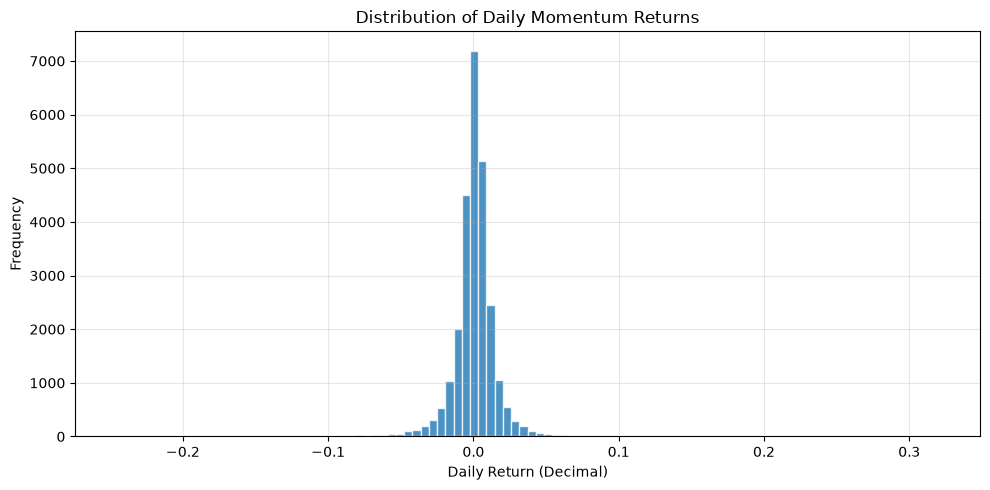

In [9]:
import matplotlib.pyplot as plt

# Plot the distribution of daily momentum returns
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    daily_clean["mom"],
    bins=100,
    edgecolor="white",
    alpha=0.8
)

ax.set_title("Distribution of Daily Momentum Returns")
ax.set_xlabel("Daily Return (Decimal)")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

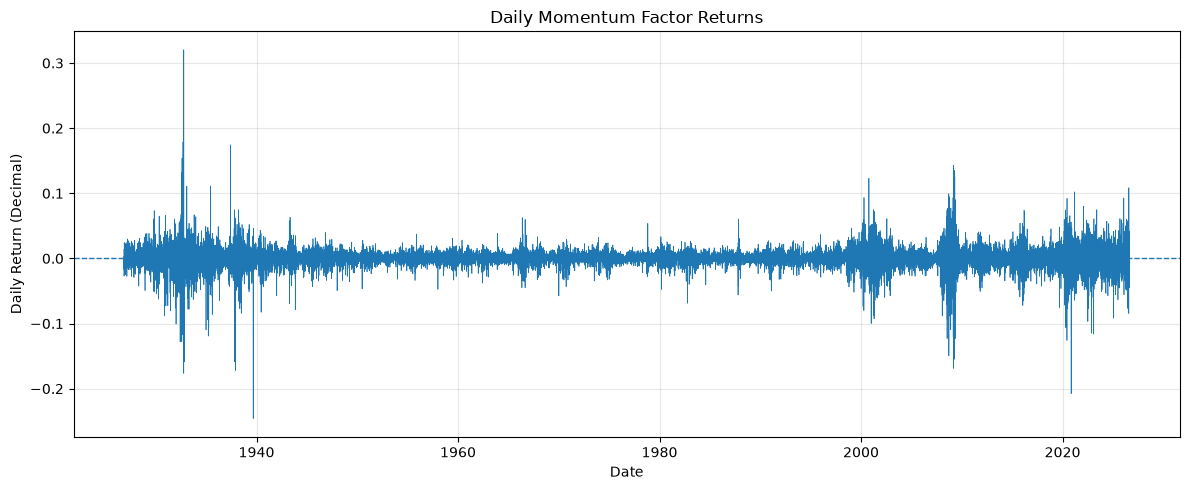

In [10]:
# Plot the daily momentum return time series
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_clean.index,
    daily_clean["mom"],
    linewidth=0.5
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title("Daily Momentum Factor Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Return (Decimal)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Load monthly momentum returns (cache-first)

The shared loader independently checks `01_momentum_monthly.parquet` and downloads only when missing. The official monthly series is not assumed to equal compounded daily factor returns.

In [11]:
monthly_df = monthly_clean.copy()
print('Monthly date range:', monthly_clean.index.min(), 'to', monthly_clean.index.max())
print('Monthly rows:', len(monthly_clean))
print(monthly_clean.head())
print(monthly_clean.tail())

Monthly date range: 1927-01 to 2026-08
Monthly rows: 1196
            mom
month          
1927-01  0.0308
1927-02 -0.0035
1927-03  0.0873
1927-04  0.0421
1927-05  0.0328
            mom
month          
2026-04  0.2517
2026-05  0.1669
2026-06  0.1545
2026-07 -0.2271
2026-08 -0.1440


In [12]:
print('Monthly index type:', type(monthly_clean.index).__name__)
print('Missing monthly returns:', monthly_clean['mom'].isna().sum())

Monthly index type: PeriodIndex
Missing monthly returns: 0


## 6. Validate monthly data

Check monthly PeriodIndex frequency, chronological order, missing values, and percentage conversion.

In [13]:
# Validate the monthly index type
assert isinstance(monthly_clean.index, pd.PeriodIndex)

# Validate monthly frequency
assert monthly_clean.index.freqstr == "M"

# Validate date uniqueness
assert monthly_clean.index.is_unique

# Validate chronological ordering
assert monthly_clean.index.is_monotonic_increasing

# Validate missing and non-finite values
assert monthly_clean["mom"].notna().all()
assert np.isfinite(monthly_clean["mom"].to_numpy()).all()

# Validate row count preservation
assert len(monthly_clean) == len(monthly_df)

print("All monthly validation checks passed!")

All monthly validation checks passed!


## 7. Check monthly coverage

A complete monthly calendar helps identify missing observations before replication.

In [14]:
# Construct the expected monthly index
expected_months = pd.period_range(
    start=monthly_clean.index.min(),
    end=monthly_clean.index.max(),
    freq="M"
)

# Identify missing calendar months
missing_months = expected_months.difference(monthly_clean.index)

print("Expected months:", len(expected_months))
print("Actual months:", len(monthly_clean))
print("Missing months:", len(missing_months))
print(missing_months)

Expected months: 1196
Actual months: 1196
Missing months: 0
PeriodIndex([], dtype='period[M]')


## 8. Compare compounded daily and official monthly returns

The series may differ because of source construction and factor rebalancing conventions. Treat differences as a diagnostic, not an automatic data error.

In [15]:
# Assign each daily observation to its calendar month
daily_with_month = daily_clean.copy()
daily_with_month["month"] = daily_with_month.index.to_period("M")

# Compound daily returns within each month
daily_compounded = (
    daily_with_month
    .groupby("month")["mom"]
    .agg(lambda x: (1 + x).prod() - 1)
)

daily_compounded.name = "daily_compounded"

# Combine compounded daily returns with official monthly returns
comparison = pd.concat(
    [
        daily_compounded,
        monthly_clean["mom"].rename("official_monthly")
    ],
    axis=1,
    join="inner"
)

# Calculate the difference
comparison["difference"] = (
    comparison["daily_compounded"]
    - comparison["official_monthly"]
)

# Inspect the comparison
print(comparison.head(10))

print("\nComparison statistics:")
print(comparison["difference"].describe())

print("\nCorrelation:")
print(
    comparison["daily_compounded"].corr(
        comparison["official_monthly"]
    )
)

print("\nMean absolute difference:")
print(comparison["difference"].abs().mean())

         daily_compounded  official_monthly  difference
month                                                  
1927-01          0.062982            0.0308    0.032182
1927-02          0.008071           -0.0035    0.011571
1927-03          0.126938            0.0873    0.039638
1927-04          0.059424            0.0421    0.017324
1927-05          0.026689            0.0328   -0.006111
1927-06          0.081662            0.0436    0.038062
1927-07          0.056860            0.0893   -0.032440
1927-08          0.002687            0.0611   -0.058413
1927-09          0.064003            0.0768   -0.012797
1927-10         -0.014336            0.0002   -0.014536

Comparison statistics:
count    1196.000000
mean       -0.000568
std         0.035461
min        -0.231621
25%        -0.013217
50%        -0.001175
75%         0.010948
max         0.351146
Name: difference, dtype: float64

Correlation:
0.8977839903197228

Mean absolute difference:
0.020561850350901967


## 9. Visualize monthly momentum returns

The first chart shows month-to-month returns; the second shows their distribution.
These plots complement the daily charts and make the frequency difference visible.

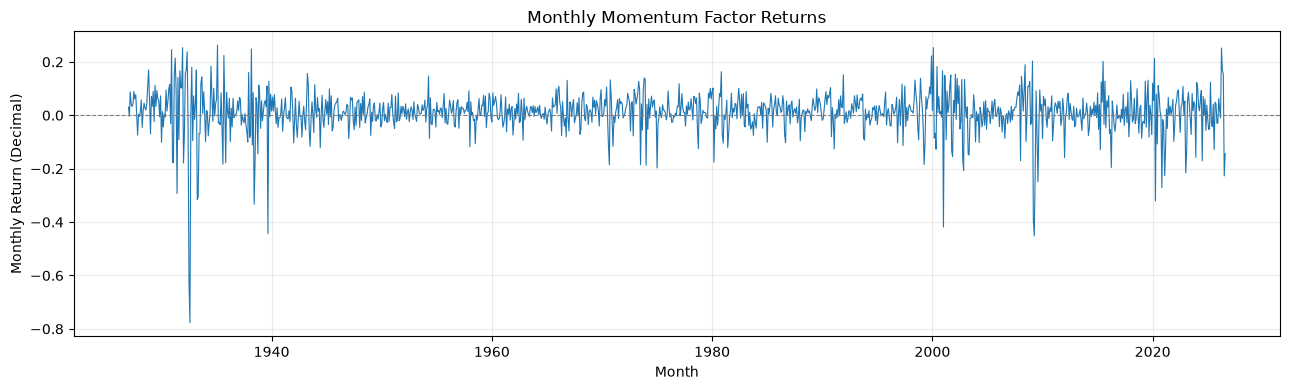

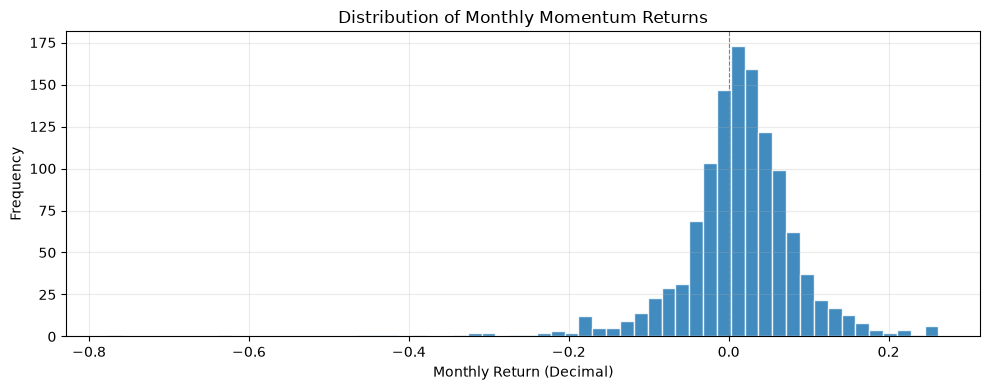

In [16]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(monthly_clean.index.to_timestamp(), monthly_clean["mom"], linewidth=0.8)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Monthly Momentum Factor Returns")
ax.set_xlabel("Month")
ax.set_ylabel("Monthly Return (Decimal)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(monthly_clean["mom"], bins=60, edgecolor="white", alpha=0.85)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Distribution of Monthly Momentum Returns")
ax.set_xlabel("Monthly Return (Decimal)")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Confirm cache files

The shared Python loader creates `kf_wml_deciles_daily_vw.parquet` and `kf_wml_deciles_monthly_vw.parquet` on a cache miss. Verify the saved files without re-downloading or duplicating persistence logic.

In [17]:
from momentum_risk_project.data import processed_path
pd.testing.assert_frame_equal(daily_clean, pd.read_parquet(processed_path("daily")))
pd.testing.assert_frame_equal(monthly_clean, pd.read_parquet(processed_path("monthly")))
print("Canonical packaged data cache checks passed.")

Canonical packaged data cache checks passed.


## 11. Reuse the packaged data API

The exploration above remains the research walkthrough. For another notebook, script or frontend, call the shared loader instead of copying the download/cleaning cells:

- `data.load_wml_decile_returns(refresh=False)` returns **two Series**, daily then monthly, both named `wml`. Daily dates use a `DatetimeIndex`; monthly dates use a monthly `PeriodIndex`. Values are decimal simple returns for value-weighted **P10 minus P1**, not the separate 2-by-3 Mom factor.
- `data.load_momentum_returns(refresh=False)` returns the same data as two **DataFrames** with a `mom` column, matching this notebook's `daily_clean` and `monthly_clean` objects.
- With `refresh=False`, valid existing canonical caches are reused. On a cache miss the loader downloads from KF and writes the canonical raw/processed caches; network access is then needed. `refresh=True` explicitly replaces those canonical caches with a new download. It is not required for ordinary reuse.
- For an exact frozen raw snapshot, use `data.clean_momentum(raw_deciles, "daily" or "monthly")`; it validates ten columns, computes the spread and converts percentages to decimals without downloading or saving.

The cell below loads the existing canonical caches and verifies that the Series API reproduces the inputs explored above. It does not create another export or change the analysis variables. The loader's canonical processed filenames are `kf_wml_deciles_daily_vw.parquet` and `kf_wml_deciles_monthly_vw.parquet`; the earlier `01_momentum_*` files are separate retained notebook snapshots, not this loader's current output names.

In [18]:
from momentum_risk_project.data import load_wml_decile_returns

api_daily_wml, api_monthly_wml = load_wml_decile_returns(refresh=False)
pd.testing.assert_series_equal(api_daily_wml, daily_clean["mom"], check_names=False)
pd.testing.assert_series_equal(api_monthly_wml, monthly_clean["mom"], check_names=False)

print("Packaged data loader matches this notebook's daily and monthly inputs.")
print("Daily API: Series, DatetimeIndex, decimal P10-P1 returns")
print("Monthly API: Series, monthly PeriodIndex, decimal P10-P1 returns")
display(api_monthly_wml.tail().to_frame("monthly_wml"))

Packaged data loader matches this notebook's daily and monthly inputs.
Daily API: Series, DatetimeIndex, decimal P10-P1 returns
Monthly API: Series, monthly PeriodIndex, decimal P10-P1 returns


,monthly_wml
month,
2026-04,0.2517
2026-05,0.1669
2026-06,0.1545
2026-07,-0.2271
2026-08,-0.1440


**Next step:** pass daily WML to `volatility.historical_volatility` and monthly WML to `strategies.volatility_managed_momentum`, as demonstrated in Notebook 02's final API guide. Keep official monthly P10-P1 returns as the monthly strategy input; compounding the daily long-short spread is not a replacement for the monthly portfolio return. Notebook 03 provides the distinct stock-construction API; Notebook 05 adds constituent-stock trading costs.

## Package tests and notebook validation

Run these commands **in a terminal from the repository root**, using the project environment. The focused suite covers data loaders, cleaning, validation and caching:

```bash
uv run pytest -p no:cacheprovider tests/test_data.py -q
```

Run the complete existing suite before integration:

```bash
uv run pytest -p no:cacheprovider tests/ -q
uv run pytest tests/test_pipeline.py -q
```

Unit tests use synthetic/local fixtures and do not require WRDS credentials or live market-data downloads. They validate implementation behavior; they do not establish equivalence to a particular CRSP/KF vintage or resolve missing economic payoffs. The executed API examples above additionally validate the shown notebook/data comparisons and require their documented local inputs. These checks are distinct from executing the entire notebook on the full research sample. If parameters, source inputs or valuation conventions change, rerun the relevant notebook and its comparisons as well as the tests. Planned EWMA/GARCH files and tests are not part of these implemented commands.